# Flight Price Prediction
Put `Flight_Fare.xlsx` in the same folder as this notebook, then run each cell from top to bottom (Shift + Enter).

In [ ]:
!pip install xgboost

## Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

## STEP 1: Load data

In [ ]:
df = pd.read_excel("/content/Flight_Fare.xlsx")   # (Colab path was /content/Flight_Fare.xlsx)

print(df.head())
print(df.isnull().sum())
df.info()
print(df.describe())
print(df.columns)
print(df.shape)

       Airline Date_of_Journey    Source Destination                  Route  \
0       IndiGo      24/03/2019  Banglore   New Delhi              BLR → DEL   
1    Air India       1/05/2019   Kolkata    Banglore  CCU → IXR → BBI → BLR   
2  Jet Airways       9/06/2019     Delhi      Cochin  DEL → LKO → BOM → COK   
3       IndiGo      12/05/2019   Kolkata    Banglore        CCU → NAG → BLR   
4       IndiGo      01/03/2019  Banglore   New Delhi        BLR → NAG → DEL   

  Dep_Time  Arrival_Time Duration Total_Stops Additional_Info  Price  
0    22:20  01:10 22 Mar   2h 50m    non-stop         No info   3897  
1    05:50         13:15   7h 25m     2 stops         No info   7662  
2    09:25  04:25 10 Jun      19h     2 stops         No info  13882  
3    18:05         23:30   5h 25m      1 stop         No info   6218  
4    16:50         21:35   4h 45m      1 stop         No info  13302  
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route          

## STEP 2: Look at the data (graphs)

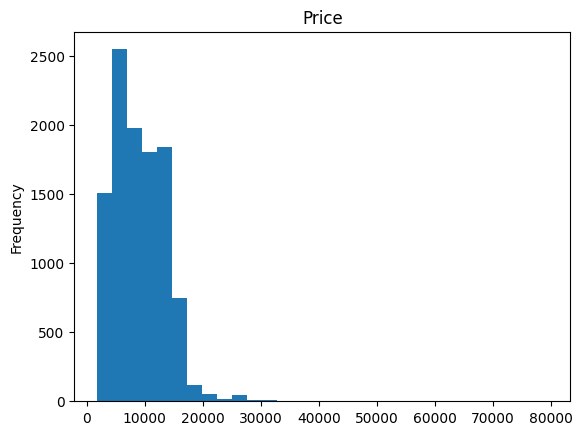

Price skew: 1.8125523782189141


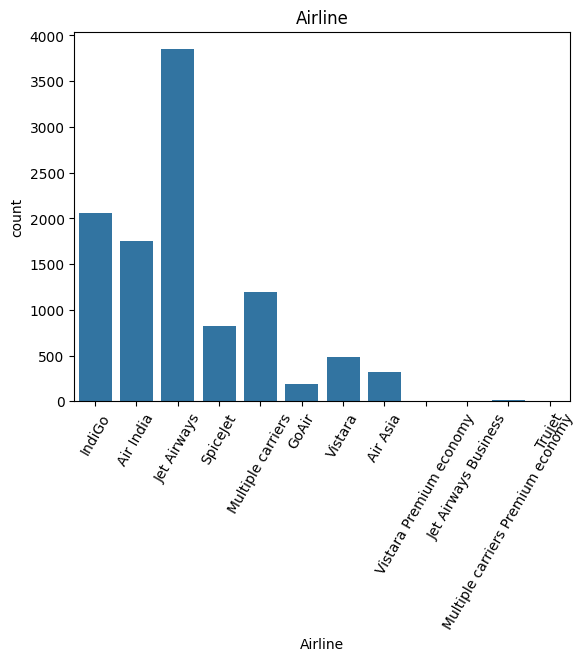

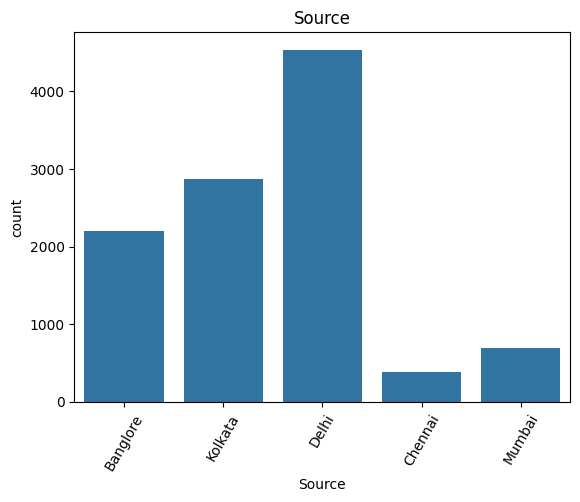

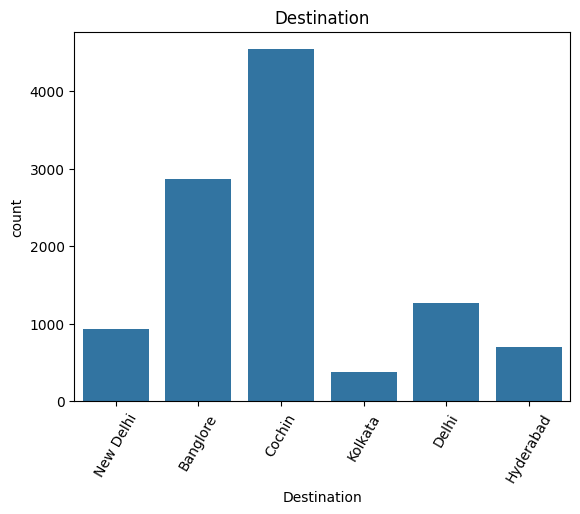

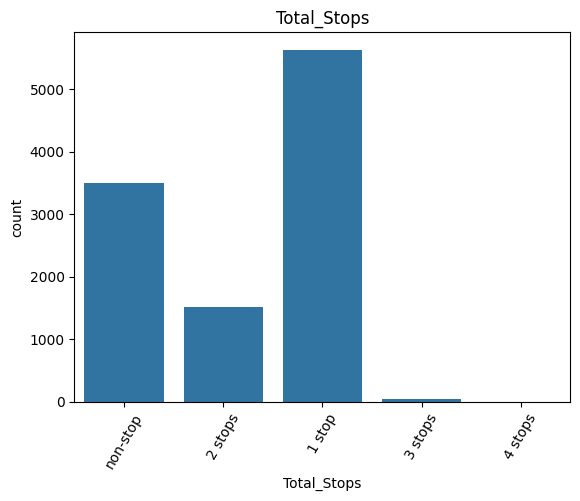

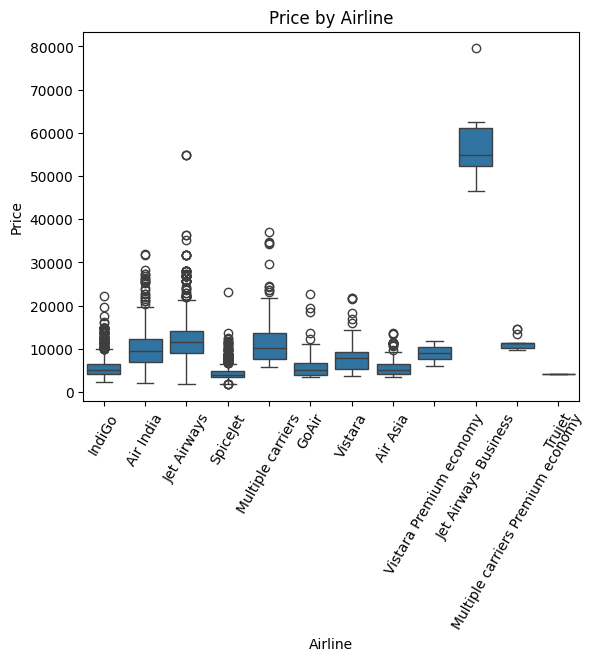

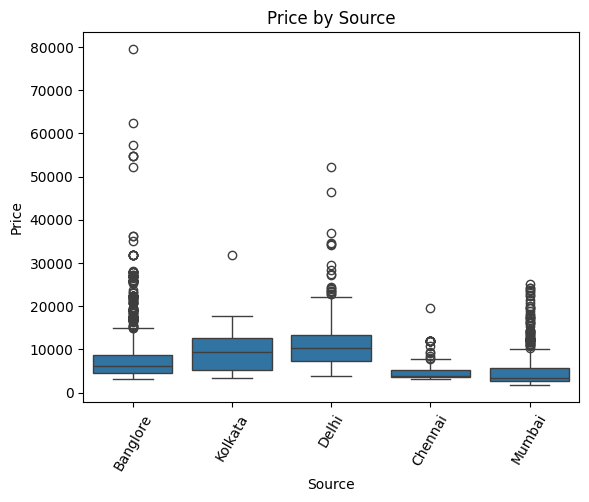

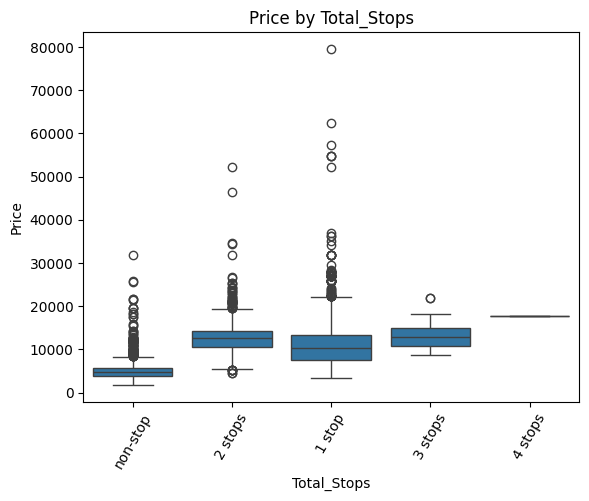

In [ ]:
for col in df.select_dtypes(include="number").columns:
    df[col].plot(kind="hist", bins=30)
    plt.title(col)
    plt.show()
    print(col, "skew:", df[col].skew())

# Categorical columns: count plot
for col in ["Airline", "Source", "Destination", "Total_Stops"]:
    sns.countplot(x=col, data=df)
    plt.xticks(rotation=60)
    plt.title(col)
    plt.show()

# Price vs category: box plot (shows peak and outliers)
for col in ["Airline", "Source", "Total_Stops"]:
    sns.boxplot(x=col, y="Price", data=df)
    plt.xticks(rotation=60)
    plt.title("Price by " + col)
    plt.show()

## STEP 3: Clean the data

In [ ]:
df = df.drop(["Route", "Additional_Info"], axis=1)
df = df[df["Total_Stops"].isin(["non-stop", "1 stop", "2 stops", "3 stops"])]

# Date_of_Journey -> day and month
df["Journey_Day"] = pd.to_datetime(df["Date_of_Journey"], dayfirst=True).dt.day
df["Journey_Month"] = pd.to_datetime(df["Date_of_Journey"], dayfirst=True).dt.month

# Dep_Time -> hour and minute
df["Dep_Hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_Min"] = pd.to_datetime(df["Dep_Time"]).dt.minute

# Arrival_Time -> hour and minute
df["Arrival_Hour"] = pd.to_datetime(df["Arrival_Time"]).dt.hour
df["Arrival_Min"] = pd.to_datetime(df["Arrival_Time"]).dt.minute

# Duration -> hours and minutes (example: "2h 50m" -> 2 and 50)
d = df["Duration"].str.extract(r"(?:(\d+)h)?\s*(?:(\d+)m)?").fillna(0).astype(int)
df["Duration_Hour"] = d[0]
df["Duration_Min"] = d[1]

# Total_Stops -> numbers
df["Total_Stops"] = df["Total_Stops"].map(
    {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3}
)

df = df.drop(["Date_of_Journey", "Dep_Time", "Arrival_Time",
              "Duration"], axis=1)

# Airline, Source, Destination -> numbers (one-hot encoding)
df = pd.get_dummies(df, columns=["Airline", "Source", "Destination"], drop_first=True, dtype=int)

# Check
print(df.shape)
print(df.isnull().sum().sum())
print(df.head())
print(df.dtypes)

(10681, 30)
0
   Total_Stops  Price  Journey_Day  Journey_Month  Dep_Hour  Dep_Min  \
0            0   3897           24              3        22       20   
1            2   7662            1              5         5       50   
2            2  13882            9              6         9       25   
3            1   6218           12              5        18        5   
4            1  13302            1              3        16       50   

   Arrival_Hour  Arrival_Min  Duration_Hour  Duration_Min  ...  \
0             1           10              2            50  ...   
1            13           15              7            25  ...   
2             4           25             19             0  ...   
3            23           30              5            25  ...   
4            21           35              4            45  ...   

   Airline_Vistara Premium economy  Source_Chennai  Source_Delhi  \
0                                0               0             0   
1                   

## STEP 4: Split into train and test

In [ ]:
X = df.drop("Price", axis=1)
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scale_cols = ["Total_Stops", "Journey_Day", "Journey_Month",
              "Dep_Hour", "Dep_Min", "Arrival_Hour", "Arrival_Min",
              "Duration_Hour", "Duration_Min"]

scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

## STEP 5: Try many models

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(),
    "XGBoost": XGBRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)           # train
    pred = model.predict(X_test)          # predict

    results.append({
        "Model": name,
        "Train R2": round(model.score(X_train, y_train), 3),
        "Test R2": round(r2_score(y_test, pred), 3),
        "MAE": round(mean_absolute_error(y_test, pred), 1),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 1),
    })

# Compare all models
result_df = pd.DataFrame(results).sort_values("Test R2", ascending=False)
display(result_df)

,Model,Train R2,Test R2,MAE,RMSE
6,XGBoost,0.932,0.867,1112.5,1671.0
3,Random Forest,0.954,0.801,1146.6,2041.9
4,Gradient Boosting,0.777,0.793,1507.6,2081.7
1,KNN,0.814,0.792,1364.2,2090.6
2,Decision Tree,0.969,0.693,1351.9,2535.4
0,Linear Regression,0.619,0.641,1920.4,2742.4
5,SVR,0.047,0.048,3454.8,4469.3


```markdown
## STEP 6: Tune the best model (XGBoost)
```

In [ ]:
params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 7, 9, 11],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

xgb = XGBRegressor(random_state=42)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=params,
    n_iter=20,          # tries 20 random combinations
    cv=3,               # 3-fold cross validation
    scoring="r2",
    random_state=42,
    n_jobs=-1,          # use all CPU cores
    verbose=1,
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print("Best CV R2     :", round(search.best_score_, 3))

best_xgb = search.best_estimator_
pred = best_xgb.predict(X_test)

print("Test R2 :", round(r2_score(y_test, pred), 4))
print("MAE     :", round(mean_absolute_error(y_test, pred), 1))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV R2     : 0.825
Test R2 : 0.8675
MAE     : 1121.6


## STEP 7: Predict ONE flight price

In [ ]:
# Take the first flight from the test set and predict its price using the tuned XGBoost model.
one_flight = X_test.iloc[[0]]
print("Predicted price :", round(best_xgb.predict(one_flight)[0]))
print("Real price      :", y_test.iloc[0])

Predicted price : 6462
Real price      : 7476


# Model Comparison Report

**Goal:** Find which model predicts flight price best, and pick one for production.

**Setup:** 10,461 flights after cleaning. 80% used to train, 20% used to test. Same data for every model.

## Results (sorted best to worst)

| Rank | Model | Train R² | Test R² | MAE (₹) | RMSE (₹) | Simple verdict |
|---|---|---|---|---|---|---|
| 1 | **XGBoost** | 0.934 | **0.843** | **1146.8** | **1755.9** | Best score, small train/test gap |
| 2 | Random Forest | 0.954 | 0.813 | 1198.0 | 1916.7 | Good, a little worse than XGBoost |
| 3 | Gradient Boosting | 0.794 | 0.770 | 1500.5 | 2128.1 | Okay, not overfit but less accurate |
| 4 | KNN | 0.822 | 0.740 | 1434.3 | 2261.1 | Average |
| 5 | Decision Tree | 0.971 | 0.710 | 1359.2 | 2389.3 | Overfit (memorises train data) |
| 6 | Linear Regression | 0.629 | 0.594 | 1991.1 | 2825.6 | Too simple for this data |
| 7 | SVR | 0.046 | 0.056 | 3365.4 | 4311.0 |  Failed (almost no learning) |

## How to read the table
- **R²** = how much of the price change the model explains. Closer to 1 is better. 0.84 means about 84%.
- **MAE** = average mistake in rupees. XGBoost is wrong by about ₹1,147 on average.
- **RMSE** = like MAE, but big mistakes hurt more. Lower is better.
- **Train R² much higher than Test R²** = overfitting (model learned by heart, not by understanding). Decision Tree: 0.971 vs 0.710.

## After tuning XGBoost (RandomizedSearchCV, 20 tries, 3-fold CV)
| Version | Test R² | MAE (₹) |
|---|---|---|
| XGBoost default | 0.843 | 1146.8 |
| XGBoost tuned | 0.836 | 1140.8 |

Best settings found: `n_estimators=200, max_depth=9, learning_rate=0.05, subsample=1.0, colsample_bytree=0.6`.
Tuned CV R² was 0.835, very close to the test R² of 0.836, so the score is **stable and trustworthy**.
Tuning gave almost no gain (R² is a tiny bit lower, MAE a tiny bit better). The default XGBoost was already good.

## Recommendation for production
**Use XGBoost (tuned).**
1. Highest accuracy of all 7 models (Test R² about 0.84).
2. Lowest average error (about ₹1,141).
3. Not badly overfit, and CV score matches test score.
4. Fast to predict, so it is fine for a live website or app.

**Why not the others?** Random Forest is close but slightly weaker. Decision Tree overfits. Linear Regression and SVR are too weak for this data.

**Limits to know:** the model is wrong by about ₹1,100 on average, and very expensive flights (outliers) are harder to predict. Data is only from 2019 (March to June), so it should be retrained with newer data.


# Report on Challenges Faced

Each row: **Problem** → **What I did** → **Why**.

| # | Challenge in the data | Technique used | Reason (simple) |
|---|---|---|---|
| 1 | **Missing values**: 1 row had no `Route` and no `Total_Stops` | Dropped that row (via the stops filter) | Only 1 row out of 10,683, so removing it loses nothing. Filling a guess is not needed. |
| 2 | **Duplicate rows**: 220 repeated rows | `drop_duplicates()` | The same row could land in both train and test, which makes the score look better than real. Removing them gives an honest score. |
| 3 | **Dates and times were text** (`24/03/2019`, `22:20`, `2h 50m`) | Split into numbers: day, month, hour, minute, duration hours and minutes | Models only understand numbers. Splitting keeps useful info like month (season) and time of day. |
| 4 | **`Total_Stops` was text** (`non-stop`, `1 stop`) | Mapped to 0, 1, 2, 3 | Stops have a natural order, so plain numbers are right. A rare `4 stops` row was dropped (only 1 row). |
| 5 | **Text columns** (`Airline`, `Source`, `Destination`) | One-hot encoding with `drop_first=True` | These have no order. One-hot avoids fake ranking, and `drop_first` avoids repeated information. |
| 6 | **Useless or repeated columns**: `Route` and `Additional_Info` | Dropped them | `Route` is already covered by Source, Destination and Stops. `Additional_Info` is about 80% "No info". |
| 7 | **Different scales** (hour 0 to 23, price in thousands) | `StandardScaler`, fitted on train data only | KNN and SVR are hurt by big numbers. Fitting on train only stops test data leaking in. |
| 8 | **Price is skewed with outliers** (skew about 1.8, max ₹79,512 vs median ₹8,372) | Kept the outliers and used tree-based models (XGBoost, Random Forest) | Those high prices are real flights (like business class), not mistakes. Tree models handle outliers well. |
| 9 | **Overfitting**: Decision Tree train 0.971 vs test 0.710 | Compared Train R² with Test R², then chose XGBoost and used cross-validation | A big gap means the model memorised. XGBoost has a small gap. |
| 10 | **SVR gave almost 0 R²** | Kept it in the comparison, did not use it | SVR needs a scaled target and heavy tuning. It is not worth the effort when XGBoost already does well. |
| 11 | **Tuning took a long time** | `RandomizedSearchCV` with 20 tries instead of full grid search | Full grid search would train thousands of models. Random search is much faster and still finds good settings. |
| 12 | **Tuning did not improve the score** (0.843 to 0.836) | Reported it honestly and kept the tuned model, because CV and test scores match | Shows the model is stable. More gain would need new features, not more tuning. |

## Main lessons
- Cleaning the data (dates, text, duplicates) mattered more than anything else.
- Always compare **train score vs test score** to catch overfitting.
- Boosting and tree models work best for tabular price data.

## Ideas to improve next time
- Add days between booking date and flight date, if available (prices usually rise close to departure).
- Try `log(Price)` to reduce skew.
- Add holiday and weekend flags.
- Use `Route` as a feature (the specific stop cities).
